
Operation: ('rotate', 90)
Transformation matrix:
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]

Operation: ('translate', 3, 2)
Transformation matrix:
 [[1 0 3]
 [0 1 2]
 [0 0 1]]

Operation: ('rotate', 180)
Transformation matrix:
 [[-1. -0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  1.]]

Combined matrix:
 [[-0.  1. -3.]
 [-1. -0. -2.]
 [ 0.  0.  1.]]

Final coordinates:
 [[-2. -2. -0.]
 [-3. -6. -4.]]

Verification successful!


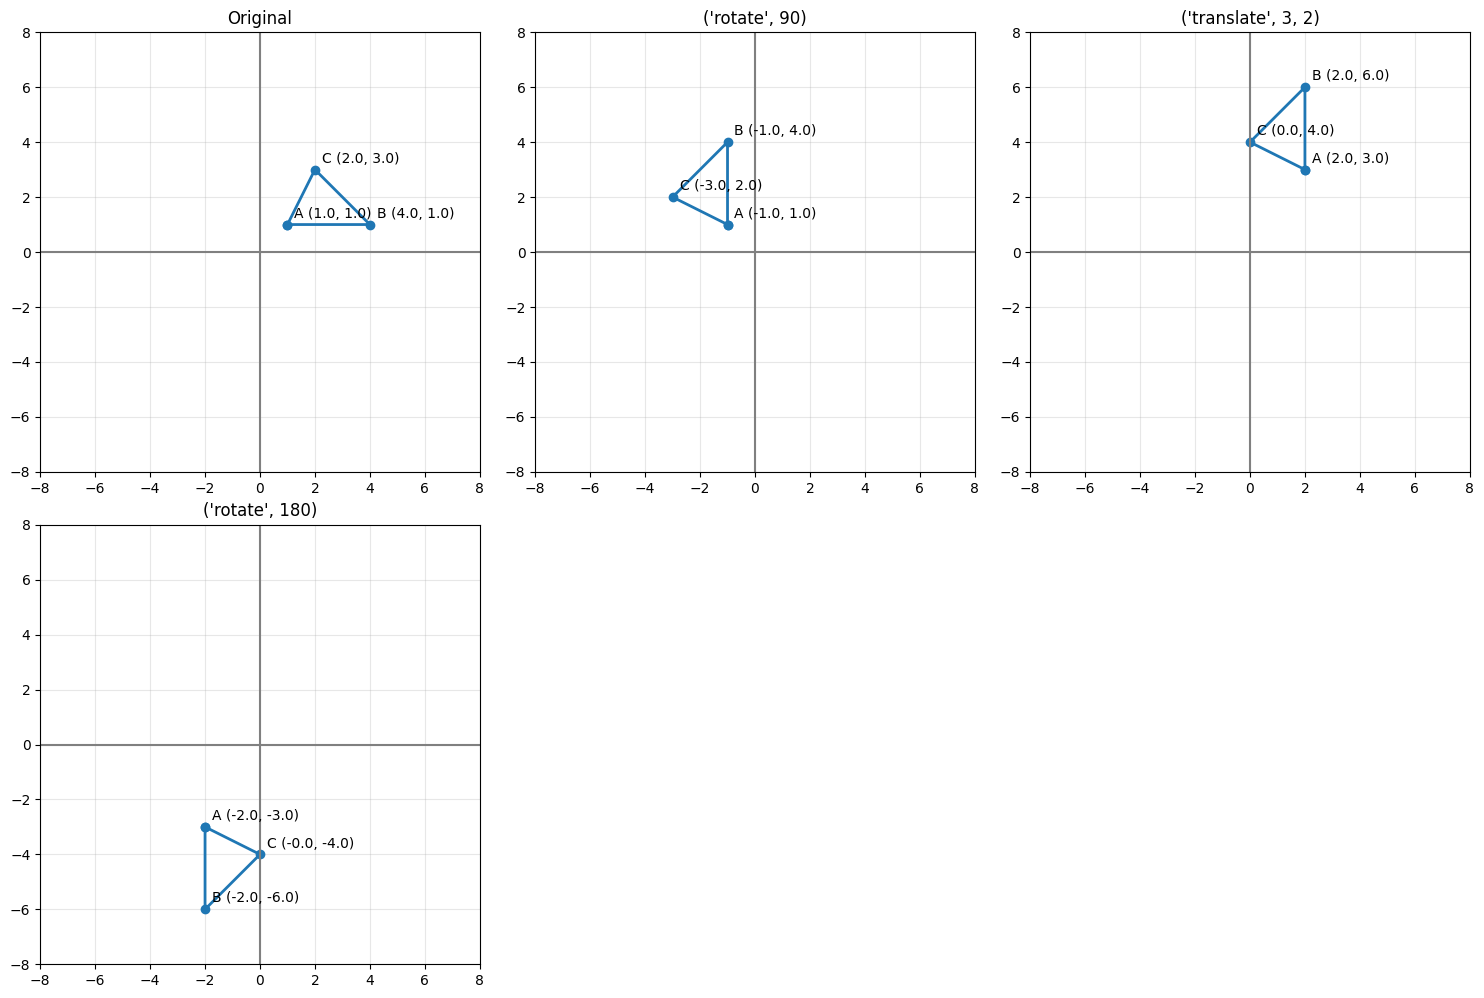

In [6]:

#2D Geometric Transformation
import numpy as np
import matplotlib.pyplot as plt

# Original triangle: every column represents a vertex
D = np.array([
    [1, 4, 2],
    [1, 1, 3]
], dtype=float)


# Convert 2D coordinates into homogeneous coordinates
def to_homogeneous(points):
    # Count the number of vertices (columns)
    num_points = points.shape[1]

    # Create one row of 1s, one for each vertex
    ones = np.ones((1, num_points))

    # Add the row underneath the x and y coordinates
    return np.vstack((points, ones))


# Convert homogeneous coordinates back to 2D
def from_homogeneous(points):
    # Divide each column's x and y by its third coordinate
    return points[:2] / points[2]


# Create a rotation matrix using an angle in degrees
def rotation_matrix(degrees):
    # Convert degrees to radians for NumPy trigonometry
    angle = np.radians(degrees)

    # Calculate cosine and sine once
    c = np.cos(angle)
    s = np.sin(angle)

    # Return the 3x3 counterclockwise rotation matrix
    return np.array([
        [c, -s, 0],
        [s,  c, 0],
        [0,  0, 1]
    ])


# Create a scaling matrix
def scaling_matrix(sx, sy):
    # sx scales horizontally, sy scales vertically
    return np.array([
        [sx, 0,  0],
        [0, sy,  0],
        [0,  0,  1]
    ])


# Create a translation matrix
def translation_matrix(tx, ty):
    # tx moves points horizontally, ty moves vertically
    return np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0,  1]
    ])


# Create a reflection matrix across the x-axis
def reflection_x_matrix():
    # Keep x unchanged, reverse the sign of y
    return np.array([
        [1,  0, 0],
        [0, -1, 0],
        [0,  0, 1]
    ])


# Create a reflection matrix across the y-axis
def reflection_y_matrix():
    # Reverse the sign of x, keep y unchanged
    return np.array([
        [-1, 0, 0],
        [ 0, 1, 0],
        [ 0, 0, 1]
    ])


# Create a horizontal shear matrix
def shear_x_matrix(k):
    # x_new = x + k*y; y stays unchanged
    return np.array([
        [1, k, 0],
        [0, 1, 0],
        [0, 0, 1]
    ])


# Create a vertical shear matrix
def shear_y_matrix(k):
    # y_new = y + k*x; x stays unchanged
    return np.array([
        [1, 0, 0],
        [k, 1, 0],
        [0, 0, 1]
    ])


# Apply any 3x3 transformation matrix to our shape
def apply_transform(points, matrix):
    # Convert ordinary coordinates to homogeneous coordinates
    homogeneous = to_homogeneous(points)

    # Apply the matrix to every vertex
    transformed = matrix @ homogeneous

    # Convert back to ordinary 2D coordinates
    return from_homogeneous(transformed)


# =====================================================
# USER-SELECTED TRANSFORMATIONS
# Change this list to experiment with different orders!
# =====================================================

operations = [
    ("rotate", 90),
    ("translate", 3, 2),
    ("rotate", 180)
]


# Convert an operation description into its matrix
def get_matrix(operation):
    # First element contains the transformation name
    name = operation[0]

    # Remaining elements contain its parameters
    params = operation[1:]

    # Choose the correct matrix based on the name
    if name == "rotate":
        return rotation_matrix(*params)

    elif name == "translate":
        return translation_matrix(*params)

    elif name == "scale":
        return scaling_matrix(*params)

    elif name == "reflect_x":
        return reflection_x_matrix()

    elif name == "reflect_y":
        return reflection_y_matrix()

    elif name == "shear_x":
        return shear_x_matrix(*params)

    elif name == "shear_y":
        return shear_y_matrix(*params)

    # Reject transformation names we haven't implemented
    else:
        raise ValueError(f"Unknown transformation: {name}")


# Start with the identity matrix (no transformation)
M = np.eye(3)

# Store the original shape as the first visualization stage
stages = [(D, "Original")]

# Process transformations in the user's chosen order
for operation in operations:

    # Construct the matrix for the current operation
    A = get_matrix(operation)

    # Place the newest matrix on the LEFT
    # This ensures the first operation acts first
    M = A @ M

    # Apply the combined matrix to the ORIGINAL shape
    current_points = apply_transform(D, M)

    # Save this stage for visualization
    stages.append((current_points, str(operation)))

    # Show the matrix used at this stage
    print(f"\nOperation: {operation}")
    print("Transformation matrix:\n", np.round(A, 3))


# Apply the final combined matrix to the original triangle
final_points = apply_transform(D, M)

# Independently apply each transformation one at a time
sequential_points = D.copy()

for operation in operations:
    # Get the matrix for the next operation
    A = get_matrix(operation)

    # Apply it to the previous stage's coordinates
    sequential_points = apply_transform(sequential_points, A)

# Verify that combining matrices matches sequential application
assert np.allclose(final_points, sequential_points)

print("\nCombined matrix:\n", np.round(M, 3))
print("\nFinal coordinates:\n", np.round(final_points, 3))
print("\nVerification successful!")


# =====================================================
# VISUALIZATION
# =====================================================

# Create one subplot for the original shape and each operation
num_plots = len(stages)

# Arrange up to 3 plots per row
cols = 3

# Calculate how many rows we need (rounding upward)
rows = (num_plots + cols - 1) // cols

# Create the plotting grid
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))

# Convert axes to a flat array, even when there's only one row
axes = np.array(axes).reshape(-1)

# Find the largest coordinate magnitude across all stages
# Add padding so transformed points remain visible
max_coord = max(
    np.max(np.abs(points))
    for points, title in stages
) + 2

# Draw each transformation stage
for ax, (points, title) in zip(axes, stages):

    # Repeat the first vertex to close the triangle
    closed = np.column_stack((points, points[:, 0]))

    # Draw the shape with connected vertices
    ax.plot(closed[0], closed[1], "-o", linewidth=2)

    # Label each vertex with its coordinates
    for label, (x, y) in zip("ABC", points.T):
        ax.annotate(
            f"{label} ({x:.1f}, {y:.1f})",
            (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )

    # Draw the x-axis and y-axis
    ax.axhline(0, color="gray")
    ax.axvline(0, color="gray")

    # Use the same coordinate limits for fair comparison
    ax.set_xlim(-max_coord, max_coord)
    ax.set_ylim(-max_coord, max_coord)

    # Keep x and y units visually equal
    ax.set_aspect("equal")

    # Show gridlines and the transformation name
    ax.grid(alpha=0.3)
    ax.set_title(title)

# Hide unused subplot spaces
for ax in axes[num_plots:]:
    ax.axis("off")

# Adjust spacing and display all plots
plt.tight_layout()
plt.show()
